# Group 3 — M2 Colab Run

This notebook is the single entry point for the M2 prototype. Use **Runtime → Run all**. Upload the submission ZIP when prompted. It runs the included tests, diagnostics, synthetic experiments, and plots.

**Scope:** synthetic data and a restricted TTT-style prototype. This is not a full reproduction of the published TTT package, not an ATP benchmark, and not proof that active-trail pruning preserves posterior skill estimates.


## 1. Upload the M2 ZIP

In [1]:
from google.colab import files
uploaded = files.upload()  # Choose M2_Group3_Final_Submission.zip from your computer
zip_names = [name for name in uploaded if name.lower().endswith('.zip')]
assert zip_names, 'Please upload the M2 final submission ZIP'
ZIP_PATH = '/content/' + zip_names[0]
print('Uploaded:', ZIP_PATH)


Saving M2_Group3_M2_Focused_Submission.zip to M2_Group3_M2_Focused_Submission.zip
Uploaded: /content/M2_Group3_M2_Focused_Submission.zip


## 2. Extract the project and install requirements

In [2]:
import os, zipfile, pathlib
with zipfile.ZipFile(ZIP_PATH) as zf:
    zf.extractall('/content')
PROJECT = '/content/M2_Group3'
if not os.path.isdir(PROJECT):
    candidates = [os.path.join('/content', d) for d in os.listdir('/content') if os.path.isdir(os.path.join('/content', d)) and os.path.isdir(os.path.join('/content', d, 'Code'))]
    if candidates: PROJECT = candidates[0]
CODE = PROJECT + '/Code'
RESULTS = PROJECT + '/Results'
assert os.path.isdir(CODE), f'Could not find expected folder: {CODE}'
os.chdir(CODE)
print('Project:', PROJECT)
print('Source files:', sorted(os.listdir(CODE + '/src')))


Project: /content/M2_Group3
Source files: ['__pycache__', 'activity_aware_extension.py', 'coursework_pgm.py', 'data_diagnostics.py', 'parameter_learning.py', 'reference_package_smoke_test.py', 'run_experiments.py', 'skill_models.py', 'test_models.py']


In [3]:
%pip install -r /content/M2_Group3/Code/requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 26.7 MB/s eta 0:00:00


## 3. Run automated tests

In [4]:
import subprocess, sys
result = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'src', '-p', 'test_*.py', '-v'], cwd=CODE, text=True, capture_output=True)
print(result.stdout)
print(result.stderr)
if result.returncode != 0:
    raise RuntimeError('At least one test failed. Inspect output above before using the results.')
print('PASS: all automated tests completed successfully.')



test_activity_aware_generator_is_reproducible_and_valid (test_models.ModelTests.test_activity_aware_generator_is_reproducible_and_valid) ... ok
test_coursework_data_audit (test_models.ModelTests.test_coursework_data_audit) ... ok
test_d_separation_chain_and_collider (test_models.ModelTests.test_d_separation_chain_and_collider) ... ok
test_filter_and_smoother_finite (test_models.ModelTests.test_filter_and_smoother_finite) ... ok
test_logloss (test_models.ModelTests.test_logloss) ... ok
test_pair_update_moves_winner_up (test_models.ModelTests.test_pair_update_moves_winner_up) ... ok
test_reproducible_generator (test_models.ModelTests.test_reproducible_generator) ... ok
test_skill_graph_diagnostics (test_models.ModelTests.test_skill_graph_diagnostics) ... ok
test_win_probability_symmetric (test_models.ModelTests.test_win_probability_symmetric) ... ok

----------------------------------------------------------------------
Ran 9 tests in 0.047s

OK

PASS: all automated tests completed succ

## 4. Run parameter learning and course-inspired diagnostics

In [5]:
def run_cmd(args):
    p = subprocess.run([sys.executable, *args], cwd=CODE, text=True, capture_output=True)
    print(p.stdout)
    if p.stderr: print(p.stderr)
    if p.returncode != 0: raise RuntimeError(f'Command failed: {args}')

run_cmd(['src/parameter_learning.py'])
run_cmd(['src/data_diagnostics.py'])
run_cmd(['src/coursework_pgm.py'])
run_cmd(['src/activity_aware_extension.py'])


Best validation setting: {'process_var': 0.25, 'beta': 1.3, 'validation_logloss': 0.5640133138940555, 'validation_matches': 60, 'seed': 42}
Full grid written: /content/M2_Group3/Results/parameter_grid.csv

{
  "seed": 42,
  "rows": 300,
  "unique_players_observed": 8,
  "missing_required_fields": 0,
  "duplicate_pair_time_keys": 0,
  "outcome_encoding": "y_a=1 means player a won; y_a=0 means player b won",
  "player_a_win_fraction": 0.5,
  "mean_absolute_true_skill_difference": 1.525837704645892,
  "correlation_true_skill_difference_vs_player_a_win": 0.6947297473011558,
  "correlation_warning": "Exploratory simulation sanity check only; correlation is not causal structure and is not computed from player IDs.",
  "input_audit_passed": true,
  "audit_errors": []
}

{
  "input_audit": {
    "n_matches": 8,
    "n_players_declared": 8,
    "n_time_steps_declared": 30,
    "n_rows_with_errors": 0,
    "errors": [],
    "player_a_win_fraction": 0.5,
    "outcome_encoding": "y_a=1 means playe

## 5. Run the reproducible synthetic benchmark

This runs the ten-seed benchmark. The included `sensitivity.csv` contains the separate sensitivity experiment from the packaged results. Regenerating all sensitivity settings is slower; if time permits, use `--sensitivity` in the command below.


In [6]:
run_cmd(['src/run_experiments.py', '--runs', '10', '--seed', '42'])
run_cmd(['../Results/make_figures.py'])


{
  "runs": 10,
  "seed_start": 42,
  "settings": {
    "players": 8,
    "time_steps": 30,
    "matches_per_time": 10,
    "skill_step_sd": 0.22,
    "beta": 1.0,
    "process_var": 0.0484
  },
  "mean": {
    "constant_logloss": 0.6931471805599453,
    "constant_brier": 0.25,
    "elo_logloss": 0.5701387717031917,
    "elo_brier": 0.19378702348933358,
    "elo_runtime_sec": 0.0006830073000003267,
    "forward_skill_mae": 0.8637276644527689,
    "forward_runtime_sec": 0.03143709430000001,
    "ttt_ep_skill_mae": 0.31792861765716474,
    "ttt_ep_runtime_sec": 0.6854890659999967,
    "forward_logloss": 0.6093744535684398,
    "forward_brier": 0.19803007866349825
  },
  "sample_sd": {
    "constant_logloss": 0.0,
    "constant_brier": 0.0,
    "elo_logloss": 0.04868334447044943,
    "elo_brier": 0.021012985596027836,
    "elo_runtime_sec": 7.182423922148145e-05,
    "forward_skill_mae": 0.1716055128166087,
    "forward_runtime_sec": 0.00995542831072684,
    "ttt_ep_skill_mae": 0.04061619

## 6. Inspect KPI summary and audit flags

In [7]:
import json, pandas as pd
from IPython.display import display, Image
with open(RESULTS + '/summary.json') as f: summary = json.load(f)
print('Mean KPIs across seeds:')
display(pd.DataFrame([summary['means']]).T.rename(columns={0:'mean'}))
print('Convergence rate:', summary['ttt_ep_convergence_rate'])
with open(RESULTS + '/data_diagnostics.json') as f: audit = json.load(f)
print('Input audit passed:', audit.get('input_audit_passed'))
print('Audit errors:', audit.get('audit_errors'))
with open(RESULTS + '/graph_diagnostics.json') as f: graph = json.load(f)
print('D-separation checks:', graph.get('d_separation_checks'))


Mean KPIs across seeds:


,mean
constant_logloss,0.693147
constant_brier,0.250000
elo_logloss,0.570139
elo_brier,0.193787
forward_logloss,0.609374
forward_brier,0.198030
forward_skill_mae,0.863728
ttt_ep_skill_mae,0.317929
elo_runtime_sec,0.000683
forward_runtime_sec,0.031437


Convergence rate: 1.0
Input audit passed: True
Audit errors: []
D-separation checks: {'skill_a_independent_of_skill_b_before_observing_result': True, 'skill_a_independent_of_skill_b_after_observing_result': False, 'skill_a_independent_of_result_given_both_performances': True}


## 7. View the plots

skill_mae_comparison.png


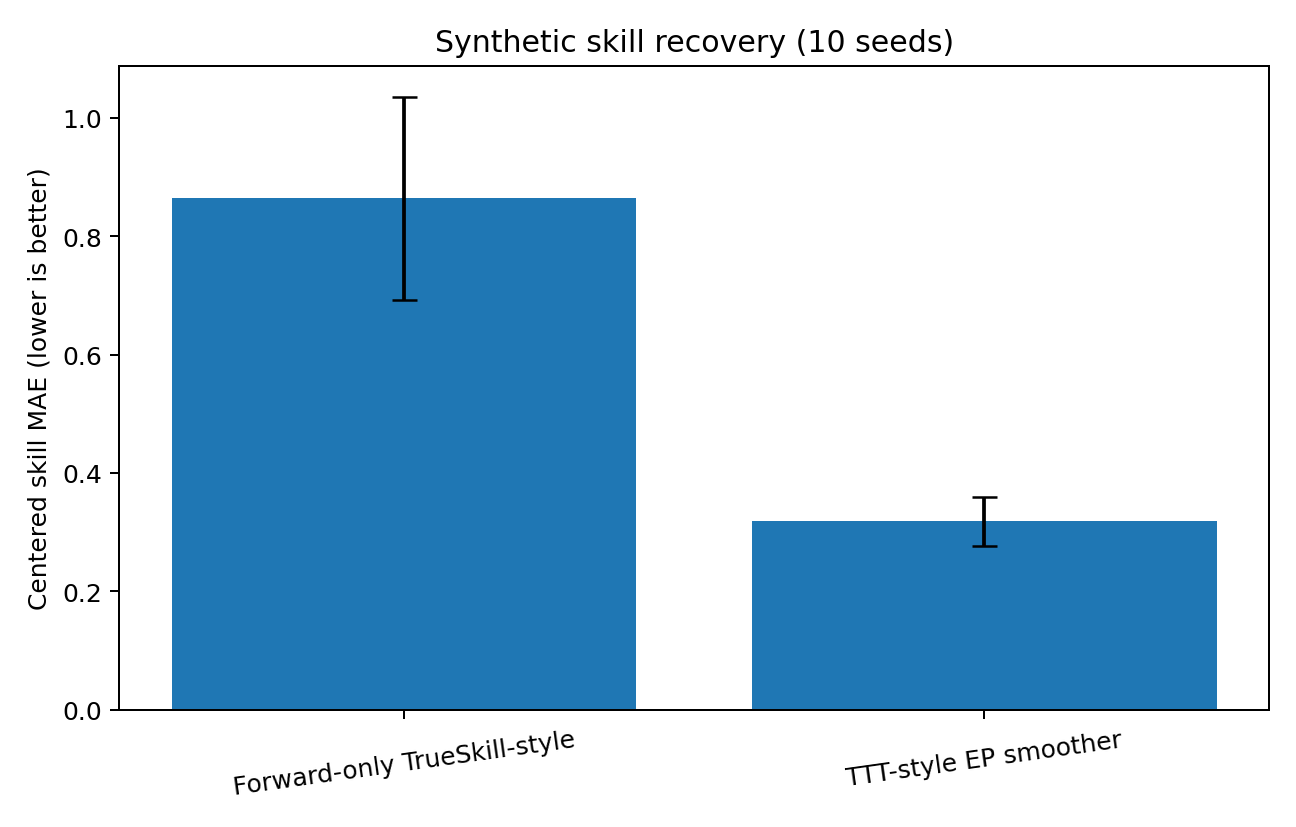

prediction_logloss.png


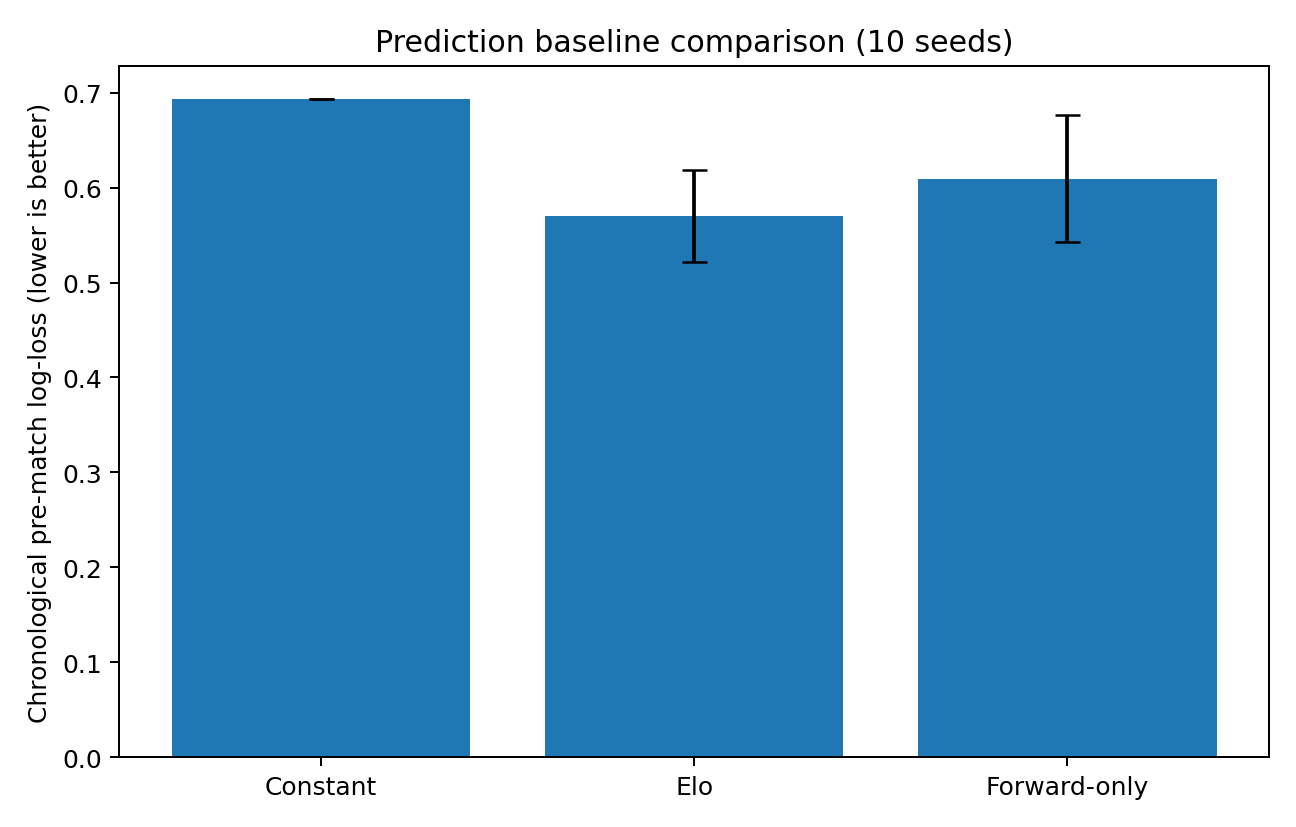

sensitivity_plot.png


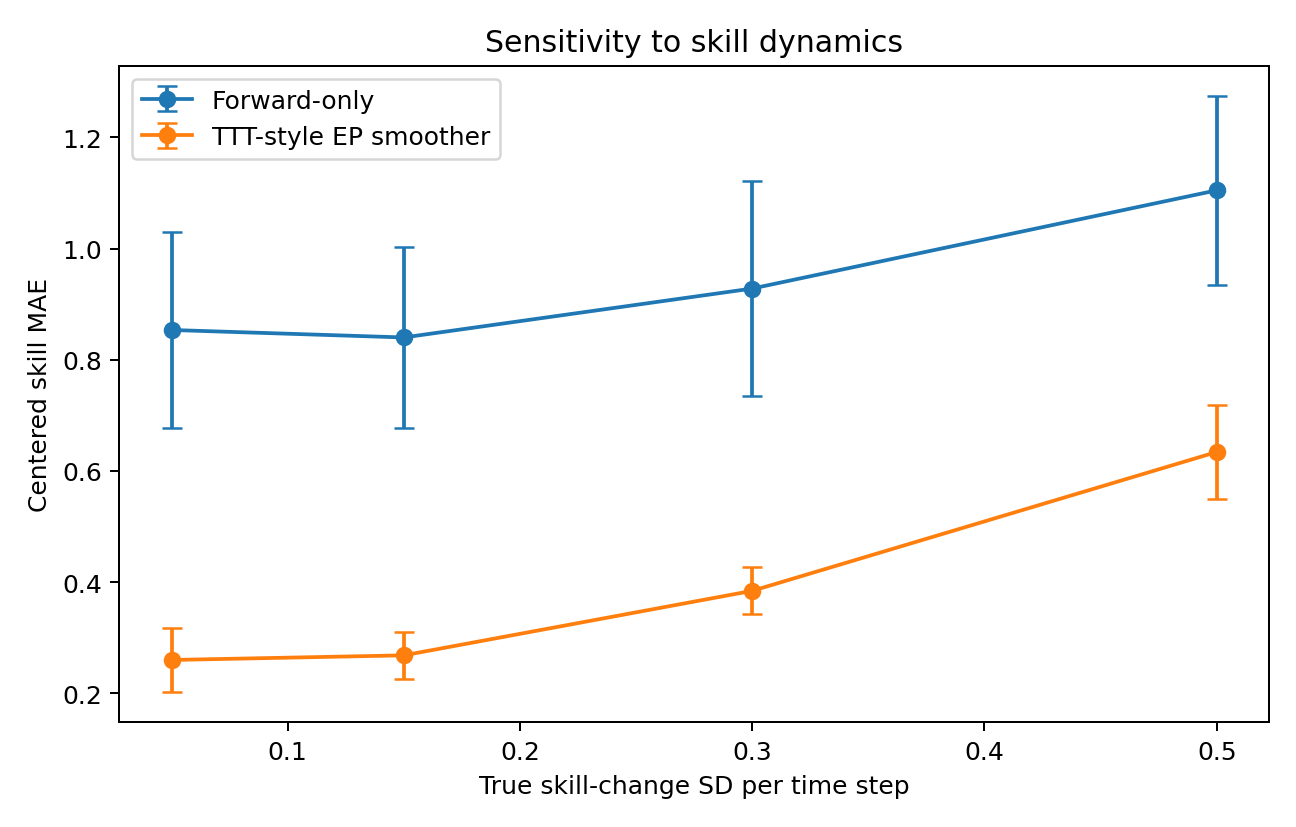

In [8]:
for filename in ['skill_mae_comparison.png', 'prediction_logloss.png', 'sensitivity_plot.png']:
    path = RESULTS + '/' + filename
    if os.path.exists(path):
        print(filename)
        display(Image(filename=path))
    else:
        print('Missing plot:', path)


## 8. How to interpret the run

A successful run should have all nine tests pass, `input_audit_passed: true`, no audit errors, finite KPI values, an activity-aware pilot CSV/JSON, and all three plots. Runtime can vary by Colab hardware.

Do not interpret a passing test suite as proof that the full published TTT method has been reproduced. This is a restricted binary two-player EP-style prototype and the current evaluation uses synthetic data. The activity-aware extension is an initial testable modification, but its five-seed pilot did not improve MAE yet. The real ATP dataset has not been evaluated.


## 9. Optional: run the reference paper package example

This optional smoke test attempts to install and run the package version of the paper’s three-event example (Codes 7–9). It is separate from our reported synthetic KPIs. If Colab has no network access or the install fails, the main M2 notebook remains valid; do not describe the package test as passed unless the output says it completed.


In [9]:
install = subprocess.run([sys.executable, "-m", "pip", "install", "trueskillthroughtime"], text=True, capture_output=True)
print(install.stdout[-3000:])
if install.returncode == 0:
    run_cmd(["src/reference_package_smoke_test.py"])
else:
    print("Optional reference-package check was not run because installation failed.")
    print(install.stderr[-1500:])



Iteration =  0 , step =  (4.93040921458863, 1.852733311513652)
Iteration =  1 , step =  (2.2678315795985924, 0.4958483671758165)
Iteration =  2 , step =  (0.8265944271289914, 0.17041196852779628)
Iteration =  3 , step =  (0.3072515004840912, 0.06137682037959147)
Iteration =  4 , step =  (0.1140554236084776, 0.022505221205031845)
Iteration =  5 , step =  (0.042248045332860466, 0.008299122092507716)
Iteration =  6 , step =  (0.015633268942690823, 0.0030654476385403306)
Iteration =  7 , step =  (0.005782487581726307, 0.001132723761075205)
Iteration =  8 , step =  (0.002138534139228517, 0.0004185729640613367)
Iteration =  9 , step =  (0.0007908607499067539, 0.00015466909844041865)
Iteration =  10 , step =  (0.00029247197378360403, 5.7150600705657695e-05)
Iteration =  11 , step =  (0.00010816235360481418, 2.111679988514581e-05)
Iteration =  12 , step =  (4.000172328518612e-05, 7.802429482062223e-06)
Iteration =  13 , step =  (1.4794265692551364e-05, 2.8828947788994697e-06)
Iteration =  14 

## 10. Save your run outputs
After the notebook finishes, this cell downloads a ZIP of the project folder, including the regenerated results and logs.

In [10]:
import shutil, os
from google.colab import files
RUN_ZIP = '/content/M2_Group3_Colab_Run_Results.zip'
shutil.make_archive(RUN_ZIP[:-4], 'zip', PROJECT)
files.download(RUN_ZIP)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>